# UrbanTales Idealized Dataset — EDA (revised)

**Scope:** EDA of the 224 idealized vertical-profile CSVs (one per case).

**Changes from the previous version**
1. The z = 0 row (every physical column NaN; only `sgsR` = 0) and the top row (z ≈ 131.5 m, dropped per the handbook) are removed before analysis.
2. The per-case mean of U over all heights is no longer used as a "wind" summary. Pedestrian-level U (interpolated at z = 1.75 m) is used instead, and the old mean is kept only to show it does not describe pedestrian-level wind.
3. Case names are parsed into layout metadata (layout type, λp, height pattern, height variation, wind direction) and joined to the case summary.
4. The `cdz` missingness is diagnosed, not just reported.
5. The spatial EDA (`_topo`, `_ped.nc`) cell runs only if those files are present in the ZIP.

**Limitation:** The profile CSVs are not the 2D pedestrian-level wind maps used as the model target. The spatial EDA still requires the `_topo` and `_ped.nc` files.

## 1. Imports and settings

In [1]:
import os, re, zipfile, shutil
from pathlib import PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

print("Ready.")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/opt/homebrew/Cellar/python@3.10/3.10.20/Frameworks/Python.framework/Versions/3.10/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/opt/homebrew/Cellar/python@3.10/3.10.20/Frameworks/Python.framework/Versions/3.10/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/Users/neerajsingh/Library/Python/3.10/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/ne

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/opt/homebrew/Cellar/python@3.10/3.10.20/Frameworks/Python.framework/Versions/3.10/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/opt/homebrew/Cellar/python@3.10/3.10.20/Frameworks/Python.framework/Versions/3.10/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/Users/neerajsingh/Library/Python/3.10/lib/python/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/ne

AttributeError: _ARRAY_API not found

Ready.


## 2. Upload the ZIP containing the idealized profile CSVs

In [2]:
from pathlib import Path
import zipfile

# Find ZIP files in Downloads
downloads = Path.home() / "Downloads"
zip_files = sorted(downloads.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("No ZIP files found in Downloads.")

# Show available ZIP files
print("Choose your idealized profile dataset ZIP:\n")

for i, file in enumerate(zip_files):
    print(f"{i}: {file.name}")

# Ask the user to select a file
choice = int(input("\nEnter the number of your dataset ZIP: "))

if not 0 <= choice < len(zip_files):
    raise ValueError("Invalid selection. Run this cell again.")

ZIP_PATH = zip_files[choice]

# Check the selected ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()

    if bad_file is not None:
        raise ValueError(f"Corrupted file inside ZIP: {bad_file}")

    csv_files = [
        name for name in zf.namelist()
        if Path(name).name.startswith("profile-")
        and name.endswith(".csv")
    ]

print("\nSelected:", ZIP_PATH.name)
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("Profile CSV files found:", len(csv_files))
print("ZIP is valid!")

Choose your idealized profile dataset ZIP:

0: 4e4e8a937d6b484e8884953cf1341b18.zip
1: 69e7391364f78_drive_download_20260421t084412z_3_001.zip
2: 7bf8c65481704bffb5ab62b49a90cd20.zip
3: Cancelled_Diverted_2023.csv.zip
4: Lab_4_Student_todo.zip
5: MCA_Modern_Computer_Architecture_Midsem_React_Website.zip
6: ProfileDemo-main.zip
7: VSCode-darwin-universal.zip
8: Zomato Dataset 2.csv.zip
9: Zomato Dataset.csv.zip
10: aa559203bbfc4e789dafa54c66dfc32d.zip
11: aml_lab-main (1).zip
12: aml_lab-main (2).zip
13: aml_lab-main (3).zip
14: aml_lab-main (4).zip
15: aml_lab-main (5).zip
16: aml_lab-main (6).zip
17: aml_lab-main (7).zip
18: aml_lab-main (8).zip
19: aml_lab-main.zip
20: archive (1).zip
21: archive.zip
22: bank+marketing.zip
23: c544629fd6b14df39ef8c177e26f9430.zip
24: cardio_train.csv.zip
25: daikibo-telemetry-data.json.zip
26: dbd220f6a27942068a76866f3d07bf82.zip
27: f79b54b552aa49fba419461411dd988f.zip
28: fake.csv.zip
29: mongosh-2.5.9-darwin-arm64 2.zip
30: mongosh-2.5.9-darwin-ar

## 3. Inventory files

In [3]:
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    all_names = zf.namelist()

csv_names = sorted(n for n in all_names if n.lower().endswith(".csv") and not n.endswith("/"))
profile_names = [n for n in csv_names if PurePosixPath(n).name.lower().startswith("profile-")]

print("All CSV files:", len(csv_names))
print("Profile CSV files:", len(profile_names))
display(pd.DataFrame({"profile_file": profile_names}).head(15))

if not profile_names:
    raise ValueError("No profile-*.csv files were found in the ZIP. Check the archive contents.")

All CSV files: 224
Profile CSV files: 224


,profile_file
0,UA0625_d00/profile-UA0625_d00.csv
1,UA0625_d45/profile-UA0625_d45.csv
2,UA1111_d00/profile-UA1111_d00.csv
3,UA1111_d45/profile-UA1111_d45.csv
4,UA16_d00/profile-UA16_d00.csv
5,UA16_d45/profile-UA16_d45.csv
6,UA25_d00/profile-UA25_d00.csv
7,UA25_d45/profile-UA25_d45.csv
8,UA35_d00/profile-UA35_d00.csv
9,UA35_d45/profile-UA35_d45.csv


## 4. Load all cases and combine them

In [4]:
frames, load_errors = [], []

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for file_name in profile_names:
        try:
            df = pd.read_csv(zf.open(file_name))
            parent = PurePosixPath(file_name).parent.name
            stem = PurePosixPath(file_name).stem
            case = parent if parent not in ("", ".") else stem.replace("profile-", "", 1)

            df["case"] = case
            match = re.search(r"_d(\d+)$", case)
            df["wind_deg"] = int(match.group(1)) if match else np.nan
            df["source_file"] = file_name
            frames.append(df)
        except Exception as exc:
            load_errors.append({"file": file_name, "error": str(exc)})

if load_errors:
    print("Files that failed to load:", len(load_errors))
    display(pd.DataFrame(load_errors))

if not frames:
    raise ValueError("No CSV files loaded successfully.")

profiles = pd.concat(frames, ignore_index=True, sort=False)
print("Files loaded:", len(frames))
print("Unique cases:", profiles["case"].nunique())
print("Combined shape:", profiles.shape)
display(profiles.head())

Files loaded: 224
Unique cases: 224
Combined shape: (29120, 34)


,Unnamed: 0,z,u,v,w,U,s,TKE,Duw,Tuw,Dvw,Tvw,Mom,ILs,vel,stdS,cdz,uGrad,sgsR,sgsM,turbT,lm,dispT,presT,shearP,wakeP,formA,Km,cklk,lece,cmu,case,wind_deg,source_file
0,0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,UA0625_d00,0,UA0625_d00/profile-UA0625_d00.csv
1,1,0.25,1.908313,0.845542,-0.000067,2.552298,0.065524,2.188223,0.032949,-0.056831,0.004460,0.072369,-0.023883,NaN,1.908320,0.999668,2.914398,NaN,-0.139233,-0.585028,NaN,NaN,NaN,NaN,NaN,0.028776,NaN,NaN,NaN,5.532996,NaN,UA0625_d00,0,UA0625_d00/profile-UA0625_d00.csv
2,2,0.75,2.967238,0.805388,-0.000097,3.392471,0.064383,2.913629,0.060402,-0.172815,0.006902,0.062812,-0.112413,2.013503,2.967239,1.302054,1.553054,1.473669,-0.242314,-0.313327,0.039787,0.001102,0.000979,0.000224,0.015917,0.030914,-9.528088e-10,0.076281,0.044689,15.872804,0.002815,UA0625_d00,0,UA0625_d00/profile-UA0625_d00.csv
3,3,1.25,3.381983,0.672585,-0.000106,3.659266,0.063940,2.994410,0.064896,-0.206454,0.007206,0.054300,-0.141558,4.489767,3.381983,1.387904,1.265345,0.753265,-0.215487,-0.245612,0.026314,0.002356,0.001080,-0.004231,0.009720,0.021366,2.951214e-11,0.187926,0.108600,21.096867,0.005148,UA0625_d00,0,UA0625_d00/profile-UA0625_d00.csv
4,4,1.75,3.720503,0.572512,-0.000104,3.932918,0.063654,3.088507,0.065305,-0.244940,0.007108,0.047247,-0.179634,6.478684,3.720504,1.443606,1.051677,0.574268,-0.211866,-0.215874,0.025910,0.003366,0.001024,-0.004061,0.008791,0.018321,-2.222356e-09,0.312806,0.177992,25.143356,0.007079,UA0625_d00,0,UA0625_d00/profile-UA0625_d00.csv


## 5. Case coverage and consistency

In [5]:
case_inventory = (
    profiles.groupby("case", dropna=False)
    .agg(
        rows=("case", "size"),
        unique_heights=("z", "nunique") if "z" in profiles.columns else ("case", "size"),
        wind_deg=("wind_deg", "first"),
        source_file=("source_file", "first")
    )
    .reset_index()
)

print("Rows per case:")
display(case_inventory["rows"].value_counts().rename_axis("rows_per_case").reset_index(name="number_of_cases"))

print("Cases not containing 130 rows:")
display(case_inventory[case_inventory["rows"] != 130])

print("Inferred wind direction:")
display(case_inventory["wind_deg"].value_counts(dropna=False).rename_axis("wind_deg").reset_index(name="cases"))

print("Case inventory preview:")
display(case_inventory.head(15))

Rows per case:


,rows_per_case,number_of_cases
0,130,224


Cases not containing 130 rows:


,case,rows,unique_heights,wind_deg,source_file


Inferred wind direction:


,wind_deg,cases
0,0,112
1,45,112


Case inventory preview:


,case,rows,unique_heights,wind_deg,source_file
0,UA0625_d00,130,130,0,UA0625_d00/profile-UA0625_d00.csv
1,UA0625_d45,130,130,45,UA0625_d45/profile-UA0625_d45.csv
2,UA1111_d00,130,130,0,UA1111_d00/profile-UA1111_d00.csv
3,UA1111_d45,130,130,45,UA1111_d45/profile-UA1111_d45.csv
4,UA16_d00,130,130,0,UA16_d00/profile-UA16_d00.csv
5,UA16_d45,130,130,45,UA16_d45/profile-UA16_d45.csv
6,UA25_d00,130,130,0,UA25_d00/profile-UA25_d00.csv
7,UA25_d45,130,130,45,UA25_d45/profile-UA25_d45.csv
8,UA35_d00,130,130,0,UA35_d00/profile-UA35_d00.csv
9,UA35_d45,130,130,45,UA35_d45/profile-UA35_d45.csv


## 5b. Clean the profiles (drop z = 0 and the top row) and parse case metadata

In [6]:
profiles_raw = profiles.copy()          # untouched copy for reference
id_cols = ["case", "wind_deg", "source_file", "z", "Unnamed: 0"]
phys_cols = [c for c in profiles.columns if c not in id_cols]

# z = 0 row: report exactly what it contains before removing it
z0 = profiles["z"] == 0
nonnull_at_z0 = profiles.loc[z0, phys_cols].notna().sum()
print("z = 0 rows:", int(z0.sum()), "(one per case)")
print("Physical columns with any non-null value at z = 0:", nonnull_at_z0[nonnull_at_z0 > 0].to_dict())
profiles = profiles[~z0]

# top row of each case (handbook: drop)
zmax = profiles.groupby("case")["z"].transform("max")
top = profiles["z"] == zmax
print("Top-row z values:", profiles.loc[top, "z"].round(3).unique())
profiles = profiles[~top].reset_index(drop=True)

print("Rows before:", len(profiles_raw), "| after:", len(profiles))
print("Rows per case after cleaning:", profiles.groupby("case").size().unique())
print("z range after cleaning:", profiles["z"].min(), "-", round(profiles["z"].max(), 2))

z = 0 rows: 224 (one per case)
Physical columns with any non-null value at z = 0: {'sgsR': 224}
Top-row z values: [131.497]
Rows before: 29120 | after: 28672
Rows per case after cleaning: [128]
z range after cleaning: 0.25 - 123.57


### Case metadata parsed from the case name
Pattern: `<U|V><A|S><lambda_p code>[-<HP>-<HH>]_d<deg>`. The λp code is read as 0625→0.0625, 1111→0.1111, 4444→0.4444, and two-digit codes as hundredths (16→0.16 … 64→0.64). **These meanings are inferred from the names; confirm them against the handbook or the `_topo` files.** If the handbook gives different definitions, edit the mappings below.

In [7]:
pat = r"^(?P<height_type>[UV])(?P<layout>[AS])(?P<lp_code>\d+)(?:-(?P<height_pattern>[A-Z]{2})-(?P<height_var>\d+))?_d(?P<deg>\d+)$"
meta = profiles["case"].drop_duplicates().str.extract(pat)
meta.insert(0, "case", profiles["case"].drop_duplicates().values)
assert meta["lp_code"].notna().all(), "Some case names did not match the expected pattern"

LP_MAP = {"0625": 0.0625, "1111": 0.1111, "16": 0.16, "25": 0.25,
          "35": 0.35, "4444": 0.4444, "53": 0.53, "64": 0.64}
meta["lambda_p"] = meta["lp_code"].map(LP_MAP)
meta["family"] = (meta["height_type"] + meta["layout"] +
                  np.where(meta["height_pattern"].notna(), "-" + meta["height_pattern"].fillna(""), ""))
meta = meta.drop(columns=["deg"])
print("Unmapped lambda_p codes:", meta.loc[meta["lambda_p"].isna(), "lp_code"].unique())
print("Cases per family:"); display(meta["family"].value_counts().sort_index().to_frame("cases"))
display(meta.head())

profiles = profiles.merge(meta.drop(columns=["lp_code"]), on="case", how="left")

Unmapped lambda_p codes: []
Cases per family:


,cases
family,
UA,16
US,16
VA-CL,32
VA-HR,32
VA-SM,32
VS-CL,32
VS-HR,32
VS-SM,32


,case,height_type,layout,lp_code,height_pattern,height_var,lambda_p,family
0,UA0625_d00,U,A,0625,NaN,NaN,0.0625,UA
128,UA0625_d45,U,A,0625,NaN,NaN,0.0625,UA
256,UA1111_d00,U,A,1111,NaN,NaN,0.1111,UA
384,UA1111_d45,U,A,1111,NaN,NaN,0.1111,UA
512,UA16_d00,U,A,16,NaN,NaN,0.1600,UA


## 6. Data types and descriptive statistics

In [8]:
print("Combined dataset shape:", profiles.shape)
display(profiles.dtypes.astype(str).rename("dtype").to_frame())
display(profiles.select_dtypes(include=np.number).describe().T)

Combined dataset shape: (28672, 40)


,dtype
Unnamed: 0,int64
z,float64
u,float64
v,float64
w,float64
U,float64
s,float64
TKE,float64
Duw,float64
Tuw,float64


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,28672.0,6.450000e+01,36.949934,1.000000,3.275000e+01,6.450000e+01,9.625000e+01,128.000000
z,28672.0,3.555445e+01,25.660882,0.250000,1.612500e+01,3.200000e+01,4.787500e+01,123.565465
u,28672.0,5.752005e+00,3.789481,-0.780174,2.742660e+00,5.423577e+00,8.330080e+00,25.137817
v,28672.0,2.252124e+00,2.867066,0.003472,9.278824e-02,6.241250e-01,4.324173e+00,18.439880
w,28672.0,-1.265921e-04,0.000282,-0.004364,-1.251625e-04,-1.961246e-10,4.706991e-11,0.001271
U,28672.0,6.758081e+00,3.919955,0.678790,3.475726e+00,6.823258e+00,9.237242e+00,26.390845
s,28672.0,5.961387e-02,0.001761,0.051768,5.858143e-02,5.960913e-02,6.070067e-02,0.069084
TKE,28672.0,2.525856e+00,0.759097,0.276975,2.078731e+00,2.669585e+00,3.073253e+00,5.097439
Duw,28672.0,-5.251178e-02,0.078032,-0.501045,-8.392576e-02,-1.598037e-02,-3.977905e-04,0.190875
Tuw,28672.0,-4.607138e-01,0.230985,-1.352640,-6.225670e-01,-5.030873e-01,-2.970494e-01,0.074051


## 7. Missing-value analysis

,missing_count,missing_pct
cdz,6976,24.330357
height_var,4096,14.285714
height_pattern,4096,14.285714
turbT,448,1.562500
presT,448,1.562500
lm,397,1.384626
Km,224,0.781250
shearP,224,0.781250
uGrad,224,0.781250
formA,224,0.781250


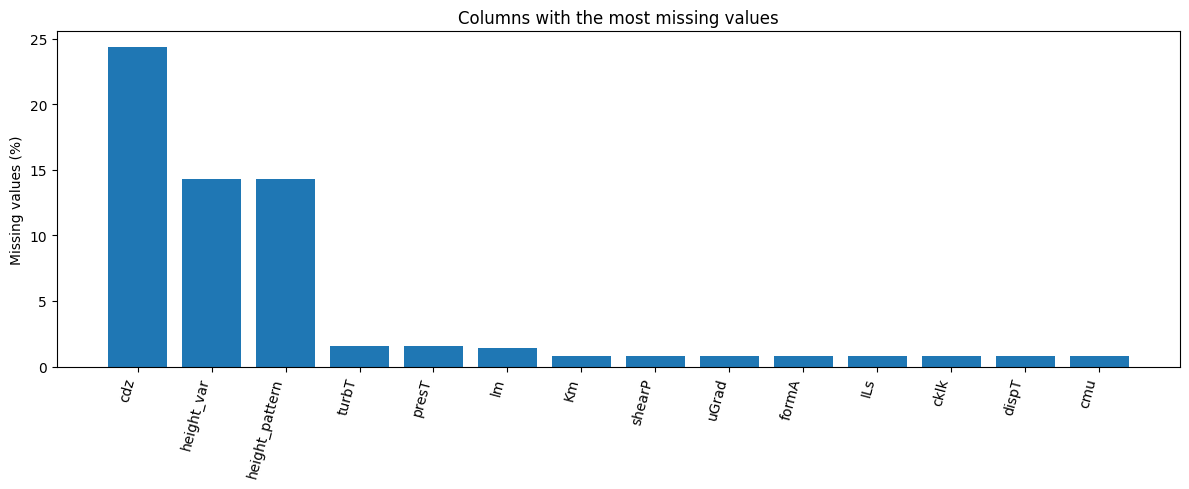

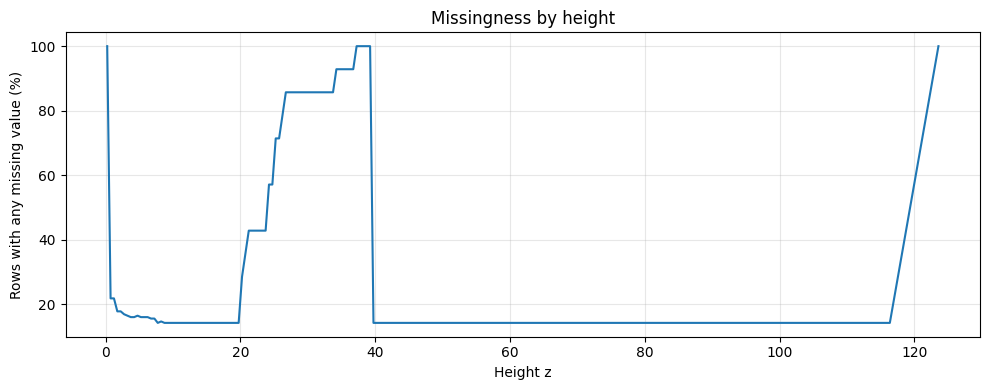

In [9]:
analysis_cols = [c for c in profiles.columns if c != "source_file"]
missing_summary = pd.DataFrame({
    "missing_count": profiles[analysis_cols].isna().sum(),
    "missing_pct": profiles[analysis_cols].isna().mean() * 100
}).sort_values("missing_pct", ascending=False)

display(missing_summary)

missing_nonzero = missing_summary[missing_summary["missing_count"] > 0]
plt.figure(figsize=(12, 5))
plt.bar(missing_nonzero.head(25).index.astype(str), missing_nonzero.head(25)["missing_pct"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("Missing values (%)")
plt.title("Columns with the most missing values")
plt.tight_layout()
plt.show()

if "z" in profiles.columns:
    data_cols_for_missing = [c for c in profiles.columns if c not in ["case", "source_file"]]
    missing_by_z = (
        profiles.assign(any_missing=profiles[data_cols_for_missing].isna().any(axis=1))
        .groupby("z", dropna=False)["any_missing"].mean().mul(100)
        .reset_index(name="rows_with_any_missing_pct")
        .sort_values("z")
    )
    plt.figure(figsize=(10, 4))
    plt.plot(missing_by_z["z"], missing_by_z["rows_with_any_missing_pct"])
    plt.xlabel("Height z")
    plt.ylabel("Rows with any missing value (%)")
    plt.title("Missingness by height")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. Duplicate rows and possible saved index

In [10]:
if "Unnamed: 0" in profiles.columns:
    print("Unnamed: 0 sample:")
    display(profiles[["case", "Unnamed: 0"]].head(10))

    def index_matches_row_order(group):
        vals = group["Unnamed: 0"].reset_index(drop=True)
        return vals.equals(pd.Series(range(len(group)), name="Unnamed: 0"))

    index_match = profiles.groupby("case", sort=False).apply(index_matches_row_order)
    print("Cases where Unnamed: 0 matches 0..n-1:", int(index_match.sum()), "/", len(index_match))

duplicate_subset = [c for c in profiles.columns if c != "source_file"]
duplicate_count = int(profiles.duplicated(subset=duplicate_subset).sum())
print("Exact duplicate rows excluding source_file:", duplicate_count)

Unnamed: 0 sample:


,case,Unnamed: 0
0,UA0625_d00,1
1,UA0625_d00,2
2,UA0625_d00,3
3,UA0625_d00,4
4,UA0625_d00,5
5,UA0625_d00,6
6,UA0625_d00,7
7,UA0625_d00,8
8,UA0625_d00,9
9,UA0625_d00,10


Cases where Unnamed: 0 matches 0..n-1: 0 / 224
Exact duplicate rows excluding source_file: 0


/var/folders/pm/gx36sgbx70jb5kh72qrxv3240000gn/T/ipykernel_37133/2713155582.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  index_match = profiles.groupby("case", sort=False).apply(index_matches_row_order)


## 9. Vertical profiles across cases

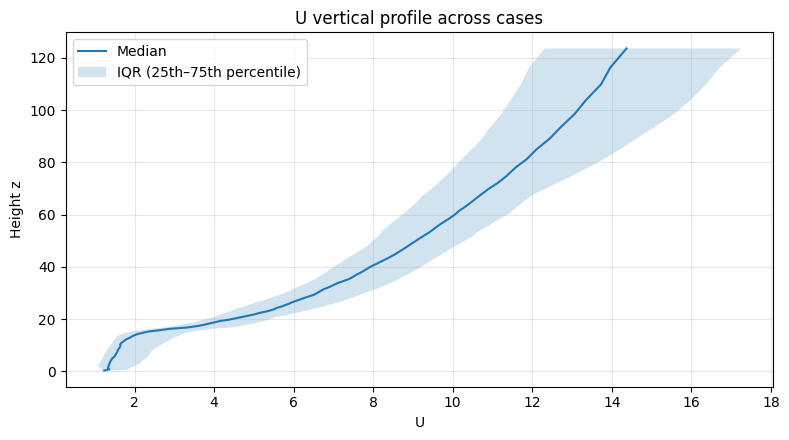

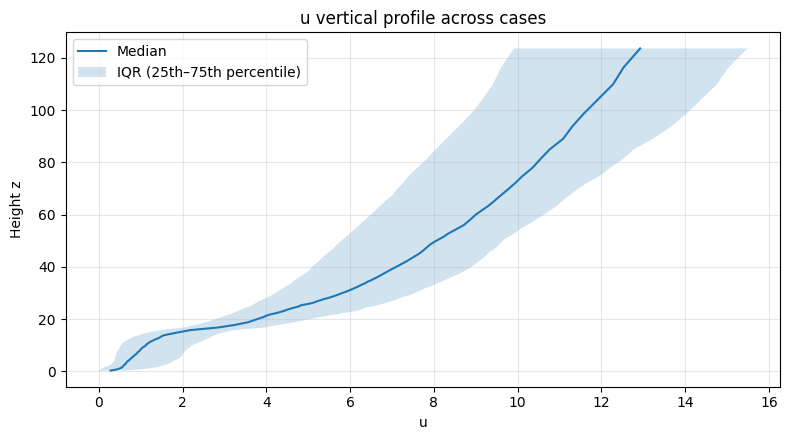

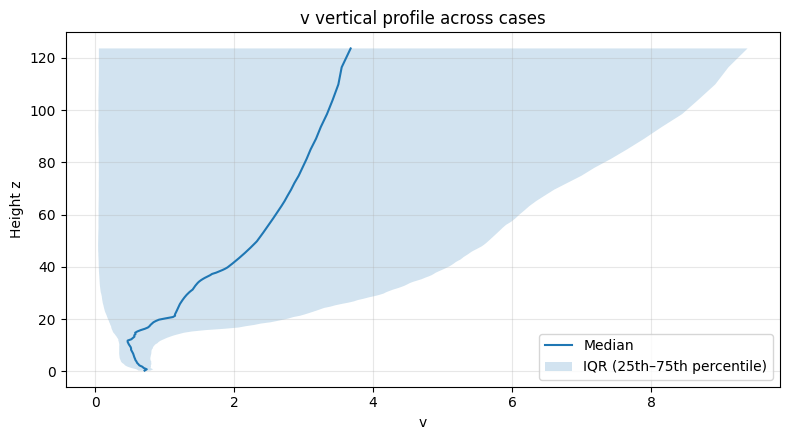

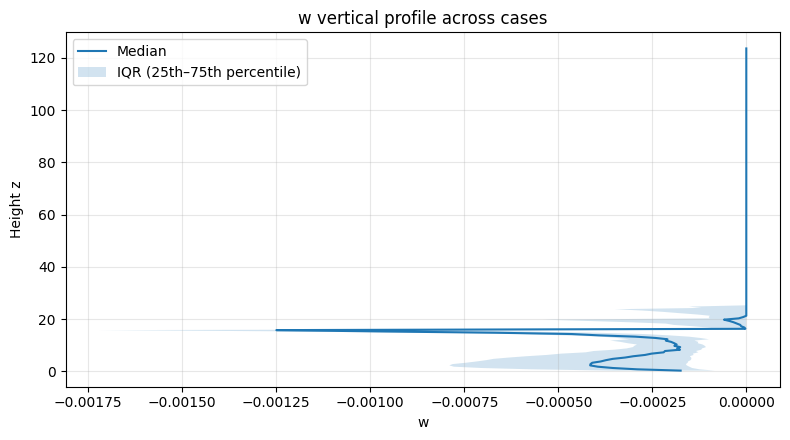

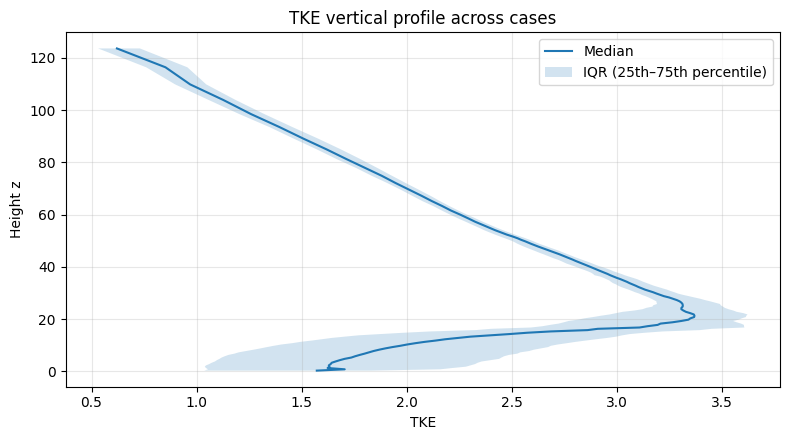

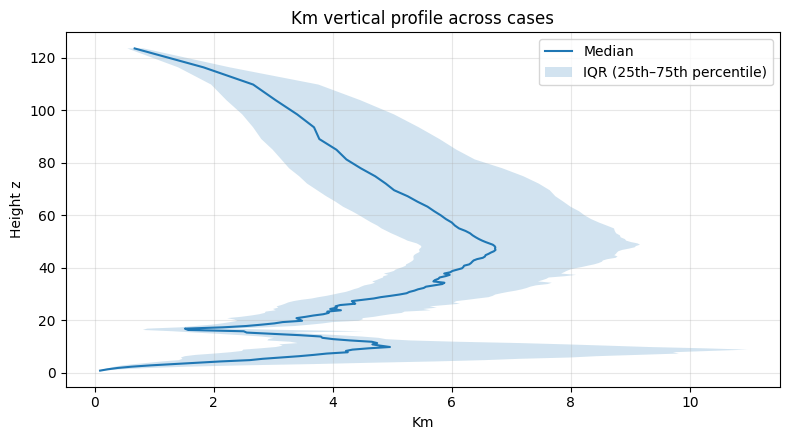

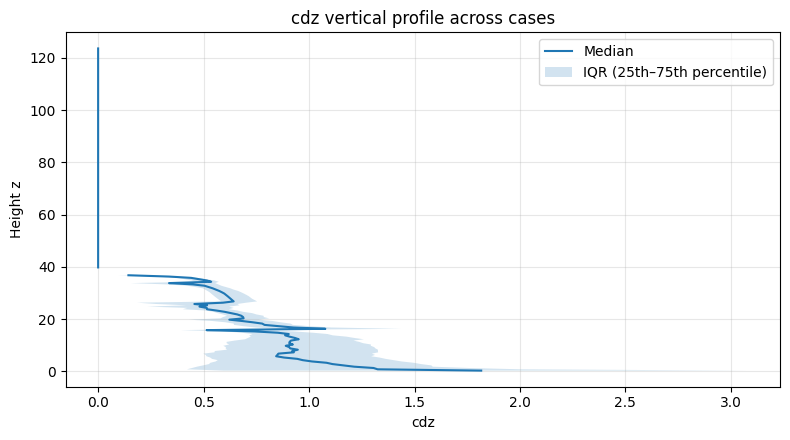

In [11]:
profile_vars = [c for c in ["U", "u", "v", "w", "TKE", "Km", "cdz"] if c in profiles.columns]

for var in profile_vars:
    summary = profiles.groupby("z")[var].agg(
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        count="count"
    ).reset_index().sort_values("z")

    plt.figure(figsize=(8, 4.5))
    plt.plot(summary["median"], summary["z"], label="Median")
    plt.fill_betweenx(summary["z"], summary["q25"], summary["q75"], alpha=0.2, label="IQR (25th–75th percentile)")
    plt.xlabel(var)
    plt.ylabel("Height z")
    plt.title(f"{var} vertical profile across cases")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10. Compare vertical profiles by wind direction

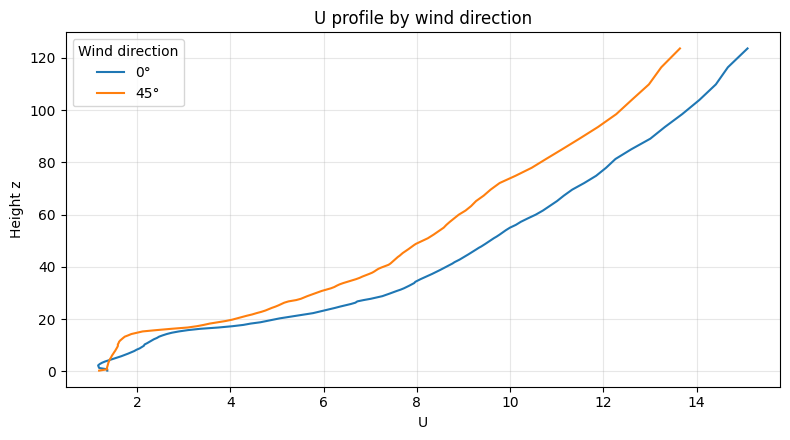

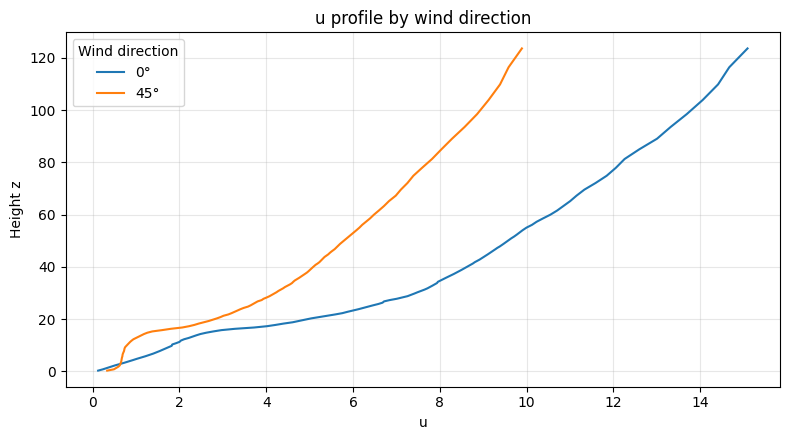

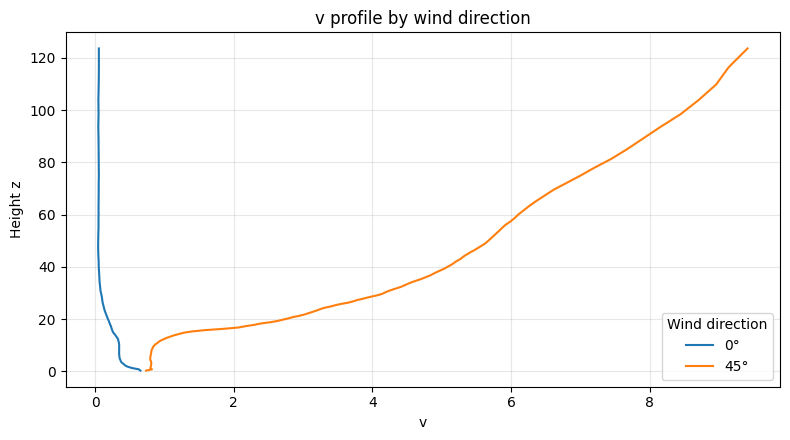

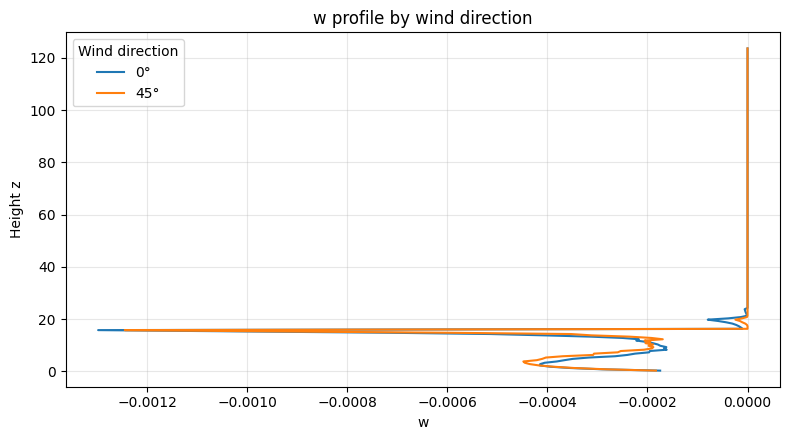

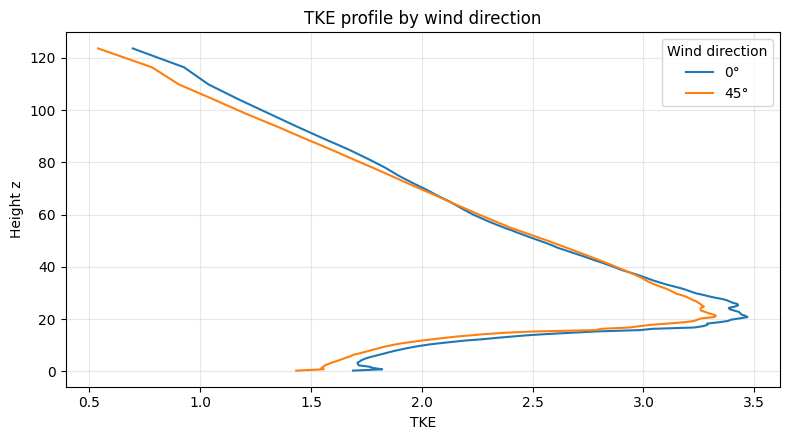

In [12]:
if "wind_deg" in profiles.columns and "z" in profiles.columns:
    for var in [c for c in ["U", "u", "v", "w", "TKE"] if c in profiles.columns]:
        grouped = profiles.groupby(["wind_deg", "z"])[var].agg(median="median", count="count").reset_index()
        plt.figure(figsize=(8, 4.5))
        for direction in sorted(grouped["wind_deg"].dropna().unique()):
            subset = grouped[grouped["wind_deg"] == direction].sort_values("z")
            plt.plot(subset["median"], subset["z"], label=f"{direction:.0f}°")
        plt.xlabel(var)
        plt.ylabel("Height z")
        plt.title(f"{var} profile by wind direction")
        plt.legend(title="Wind direction")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

## 11. Per-case profile summaries

Lowest profile level: 0.25 m (1.75 m is inside the sampled range)


/var/folders/pm/gx36sgbx70jb5kh72qrxv3240000gn/T/ipykernel_37133/4158484514.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ped = profiles.groupby("case").apply(lambda g: pd.Series({


,case,U_mean,U_ped_1p75,U_top,U_ped_over_top,lambda_p,family
0,UA0625_d00,9.105156,3.932918,14.006352,0.280795,0.0625,UA
1,UA0625_d45,6.429028,2.797551,11.249352,0.248686,0.0625,UA
2,UA1111_d00,8.276141,2.757612,14.367811,0.191930,0.1111,UA
3,UA1111_d45,5.668632,2.115069,11.218089,0.188541,0.1111,UA
4,UA16_d00,8.112201,2.188381,15.092264,0.145000,0.1600,UA


Pearson r  (U_mean all heights vs U at 1.75 m): 0.146
Spearman r (U_mean all heights vs U at 1.75 m): 0.04

10 HIGHEST pedestrian-level U (z = 1.75 m):


,case,family,lambda_p,wind_deg,U_ped_1p75,U_ped_over_top,U_mean,U_top
0,UA0625_d00,UA,0.0625,0,3.932918,0.280795,9.105156,14.006352
36,VA0625-HR-28_d00,VA-HR,0.0625,0,3.871413,0.278437,8.984128,13.904094
40,VA0625-SM-28_d00,VA-SM,0.0625,0,3.853587,0.281767,8.942619,13.676518
32,VA0625-CL-28_d00,VA-CL,0.0625,0,3.848168,0.281014,8.937158,13.693855
38,VA0625-HR-56_d00,VA-HR,0.0625,0,3.719318,0.286468,8.514742,12.983382
34,VA0625-CL-56_d00,VA-CL,0.0625,0,3.691998,0.284200,8.472293,12.990844
42,VA0625-SM-56_d00,VA-SM,0.0625,0,3.675803,0.281622,8.452114,13.052272
16,US0625_d00,US,0.0625,0,3.353825,0.271515,7.910882,12.352266
132,VS0625-HR-28_d00,VS-HR,0.0625,0,3.313401,0.277690,7.665569,11.931993
128,VS0625-CL-28_d00,VS-CL,0.0625,0,3.311988,0.270175,7.726000,12.258662


...

,case,family,lambda_p,wind_deg,U_ped_1p75,U_ped_over_top,U_mean,U_top
30,US64_d00,US,0.6400,0,0.678790,0.028880,10.727791,23.503689
29,US53_d45,US,0.5300,45,0.772033,0.035118,10.189839,21.983852
28,US53_d00,US,0.5300,0,0.772604,0.035432,9.760505,21.805361
31,US64_d45,US,0.6400,45,0.774192,0.030431,12.319238,25.440711
26,US4444_d00,US,0.4444,0,0.881802,0.045269,8.945337,19.479332
27,US4444_d45,US,0.4444,45,0.920115,0.046860,8.862159,19.635399
122,VA64-HR-56_d00,VA-HR,0.6400,0,0.949448,0.051411,6.365286,18.467819
25,US35_d45,US,0.3500,45,0.959845,0.057377,7.312695,16.728666
182,VS35-HR-56_d00,VS-HR,0.3500,0,0.963179,0.068692,5.628559,14.021703
218,VS64-HR-56_d00,VS-HR,0.6400,0,0.981373,0.059789,5.623148,16.413848


For comparison, 10 highest all-height mean U:


,case,family,lambda_p,wind_deg,U_ped_1p75,U_ped_over_top,U_mean,U_top
15,UA64_d45,UA,0.6400,45,1.206489,0.045716,12.651500,26.390845
14,UA64_d00,UA,0.6400,0,2.119463,0.084314,12.404854,25.137842
31,US64_d45,US,0.6400,45,0.774192,0.030431,12.319238,25.440711
12,UA53_d00,UA,0.5300,0,1.878056,0.083616,11.057392,22.460538
30,US64_d00,US,0.6400,0,0.678790,0.028880,10.727791,23.503689
13,UA53_d45,UA,0.5300,45,1.357690,0.060059,10.472516,22.605938
29,US53_d45,US,0.5300,45,0.772033,0.035118,10.189839,21.983852
28,US53_d00,US,0.5300,0,0.772604,0.035432,9.760505,21.805361
10,UA4444_d00,UA,0.4444,0,1.382176,0.067925,9.544937,20.348695
11,UA4444_d45,UA,0.4444,45,1.302129,0.064268,9.162570,20.261003


10 lowest all-height mean U:


,case,family,lambda_p,wind_deg,U_ped_1p75,U_ped_over_top,U_mean,U_top
171,VS25-HR-56_d45,VS-HR,0.2500,45,1.176634,0.100169,4.572887,11.746450
183,VS35-HR-56_d45,VS-HR,0.3500,45,1.034566,0.083361,4.647102,12.410696
219,VS64-HR-56_d45,VS-HR,0.6400,45,1.032088,0.069368,4.663637,14.878544
195,VS4444-HR-56_d45,VS-HR,0.4444,45,1.028656,0.077493,4.725114,13.274160
207,VS53-HR-56_d45,VS-HR,0.5300,45,1.035073,0.072509,4.740521,14.275124
99,VA4444-HR-56_d45,VA-HR,0.4444,45,1.218721,0.086205,4.843873,14.137530
111,VA53-HR-56_d45,VA-HR,0.5300,45,1.172529,0.079925,4.845760,14.670425
87,VA35-HR-56_d45,VA-HR,0.3500,45,1.274314,0.096570,4.850081,13.195730
75,VA25-HR-56_d45,VA-HR,0.2500,45,1.426937,0.115942,4.898198,12.307289
159,VS16-HR-56_d45,VS-HR,0.1600,45,1.464656,0.134049,4.920113,10.926302


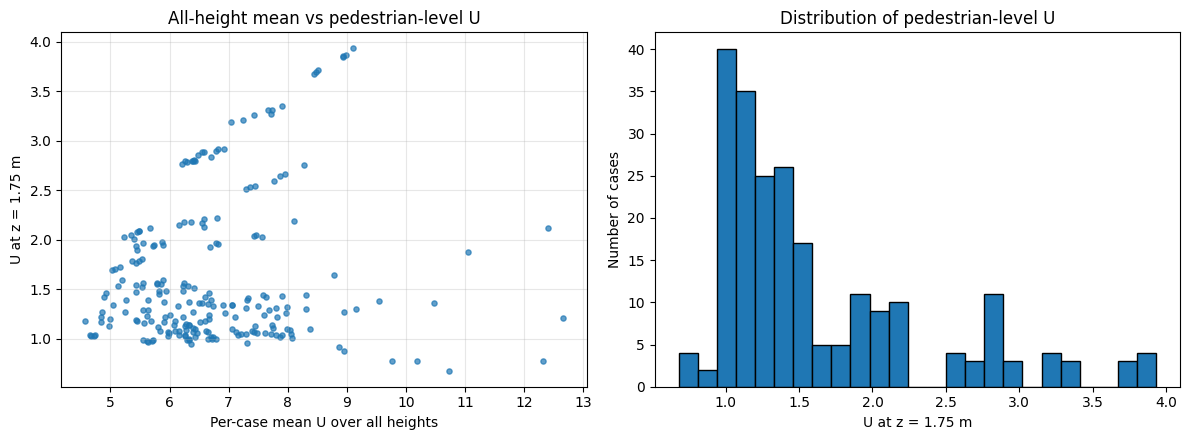

In [27]:
summary_parts = []
for var in [c for c in ["U", "u", "v", "w", "TKE", "Km", "cdz"] if c in profiles.columns]:
    tmp = profiles.groupby("case")[var].agg(["count", "mean", "median", "std", "min", "max"])
    tmp.columns = [f"{var}_{col}" for col in tmp.columns]
    summary_parts.append(tmp)
case_summary = pd.concat(summary_parts, axis=1).reset_index()

# --- pedestrian-level U: interpolate each case profile at z = 1.75 m
Z_PED = 1.75
def at_height(g, var, z_target=Z_PED):
    g = g.dropna(subset=[var]).sort_values("z")
    return np.interp(z_target, g["z"], g[var]) if len(g) else np.nan

ped = profiles.groupby("case").apply(lambda g: pd.Series({
    "U_ped_1p75": at_height(g, "U"),
    "U_top": g.sort_values("z")["U"].iloc[-1],          # highest retained level
    "U_mean_lt10m": g.loc[g["z"] <= 10, "U"].mean(),
})).reset_index()
ped["U_ped_over_top"] = ped["U_ped_1p75"] / ped["U_top"]
print("Lowest profile level:", profiles["z"].min(), "m (1.75 m is inside the sampled range)")

case_summary = (case_summary.merge(ped, on="case")
                .merge(meta.drop(columns=["lp_code"]), on="case")
                .merge(case_inventory[["case", "wind_deg", "rows", "source_file"]], on="case"))
display(case_summary[["case", "U_mean", "U_ped_1p75", "U_top", "U_ped_over_top", "lambda_p", "family"]].head())

# --- is the all-height mean a usable proxy for pedestrian-level wind?
print("Pearson r  (U_mean all heights vs U at 1.75 m):", round(case_summary["U_mean"].corr(case_summary["U_ped_1p75"]), 3))
print("Spearman r (U_mean all heights vs U at 1.75 m):", round(case_summary["U_mean"].corr(case_summary["U_ped_1p75"], method="spearman"), 3))

cols = ["case", "family", "lambda_p", "wind_deg", "U_ped_1p75", "U_ped_over_top", "U_mean", "U_top"]
print("\n10 HIGHEST pedestrian-level U (z = 1.75 m):"); display(case_summary.nlargest(10, "U_ped_1p75")[cols])
print("10 LOWEST pedestrian-level U (z = 1.75 m):");  display(case_summary.nsmallest(10, "U_ped_1p75")[cols])
print("For comparison, 10 highest all-height mean U:"); display(case_summary.nlargest(10, "U_mean")[cols])
print("10 lowest all-height mean U:");                  display(case_summary.nsmallest(10, "U_mean")[cols])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(case_summary["U_mean"], case_summary["U_ped_1p75"], s=14, alpha=0.7)
ax[0].set_xlabel("Per-case mean U over all heights"); ax[0].set_ylabel("U at z = 1.75 m")
ax[0].set_title("All-height mean vs pedestrian-level U"); ax[0].grid(alpha=0.3)
ax[1].hist(case_summary["U_ped_1p75"], bins=25, edgecolor="black")
ax[1].set_xlabel("U at z = 1.75 m"); ax[1].set_ylabel("Number of cases"); ax[1].set_title("Distribution of pedestrian-level U")
plt.tight_layout(); plt.show()

### Pedestrian-level U versus layout metadata

Mean U at 1.75 m by family:


,U_ped_1p75,U_ped_over_top,U_mean,U_top
family,,,,
UA,1.909,0.122,8.761,17.646
US,1.402,0.100,8.051,16.766
VA-CL,1.732,0.124,6.852,15.204
VA-HR,1.709,0.125,6.562,14.745
VA-SM,1.690,0.121,6.743,15.161
VS-CL,1.571,0.118,6.360,14.557
VS-HR,1.492,0.116,6.018,13.933
VS-SM,1.540,0.115,6.367,14.621


Mean U at 1.75 m by lambda_p x (height type, layout):


lambda_p            0.0625  0.1111  0.1600  0.2500  0.3500  0.4444  0.5300  0.6400
height_type layout                                                                
U           A         3.37    2.44    2.00    1.56    1.29    1.34    1.62    1.66
            S         3.14    2.09    1.53    1.07    0.98    0.90    0.77    0.73
V           A         3.28    2.32    1.87    1.43    1.25    1.19    1.16    1.16
            S         3.07    2.06    1.55    1.14    1.09    1.12    1.12    1.12

By wind direction:


,U_ped_1p75,U_ped_over_top
wind_deg,,
0,1.664,0.116
45,1.590,0.121


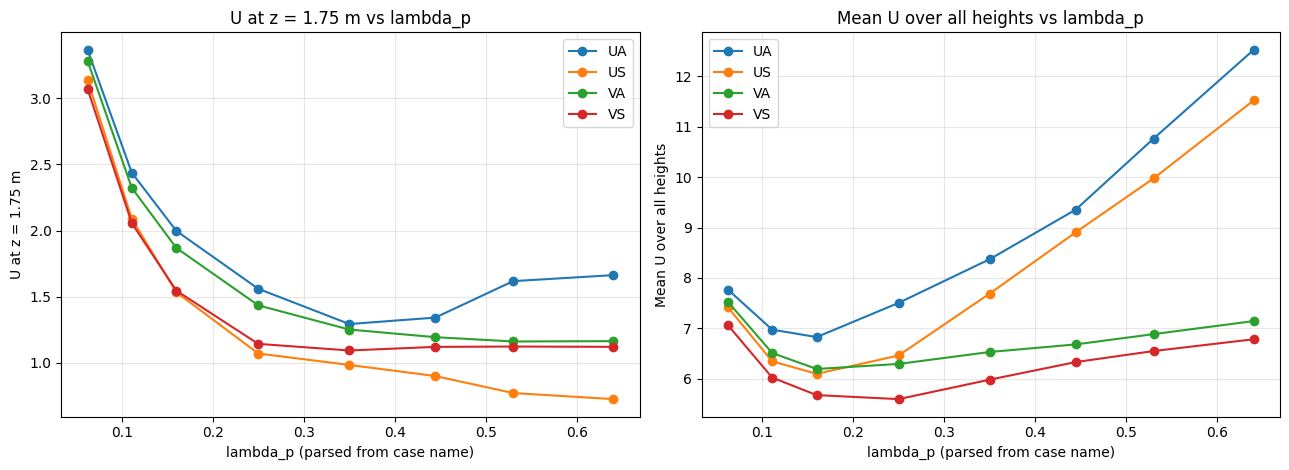

HR-pattern cases: mean U_mean = 6.29 | mean U at 1.75 m = 1.601


In [15]:
print("Mean U at 1.75 m by family:")
display(case_summary.groupby("family")[["U_ped_1p75", "U_ped_over_top", "U_mean", "U_top"]].mean().round(3))

print("Mean U at 1.75 m by lambda_p x (height type, layout):")
tab = case_summary.groupby(["height_type", "layout", "lambda_p"])["U_ped_1p75"].mean().unstack("lambda_p").round(2)
display(tab)

print("By wind direction:")
display(case_summary.groupby("wind_deg")[["U_ped_1p75", "U_ped_over_top"]].mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for (ht, lay), g in case_summary.groupby(["height_type", "layout"]):
    m_ = g.groupby("lambda_p")[["U_ped_1p75", "U_mean"]].mean()
    ax[0].plot(m_.index, m_["U_ped_1p75"], marker="o", label=f"{ht}{lay}")
    ax[1].plot(m_.index, m_["U_mean"], marker="o", label=f"{ht}{lay}")
for a, t in zip(ax, ["U at z = 1.75 m", "Mean U over all heights"]):
    a.set_xlabel("lambda_p (parsed from case name)"); a.set_ylabel(t); a.set_title(t + " vs lambda_p"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

hr = case_summary[case_summary["family"].str.endswith("HR")]
print("HR-pattern cases: mean U_mean =", round(hr["U_mean"].mean(), 3), "| mean U at 1.75 m =", round(hr["U_ped_1p75"].mean(), 3))

## 11b. Why is `cdz` missing? (diagnosis)

cdz missing after cleaning: 24.3% of rows
Cases with no cdz gap: 0 | cases entirely missing: 0
Cases whose cdz gap is a single contiguous block: 224 / 224
Distinct gap upper bounds (z): [39.25]

Gap start / length by group:


,gap_z_min,gap_z_max,gap_levels
height_type,,,
U,16.2,39.2,47.0
V,25.5,39.2,28.5


,gap_z_min,gap_z_max,gap_levels
height_pattern,,,
CL,23.4,39.2,32.8
HR,30.9,39.2,17.8
SM,22.2,39.2,35.0
NaN,16.2,39.2,47.0


,gap_z_min,gap_z_max,gap_levels
height_var,,,
28,22.4,39.2,34.7
56,28.6,39.2,22.3
NaN,16.2,39.2,47.0


,gap_z_min,gap_z_max,gap_levels
lambda_p,,,
0.0625,24.2,39.2,31.1
0.1111,24.2,39.2,31.1
0.1600,24.2,39.2,31.1
0.2500,24.2,39.2,31.1
0.3500,24.2,39.2,31.1
0.4444,24.2,39.2,31.1
0.5300,24.2,39.2,31.1
0.6400,24.2,39.2,31.1


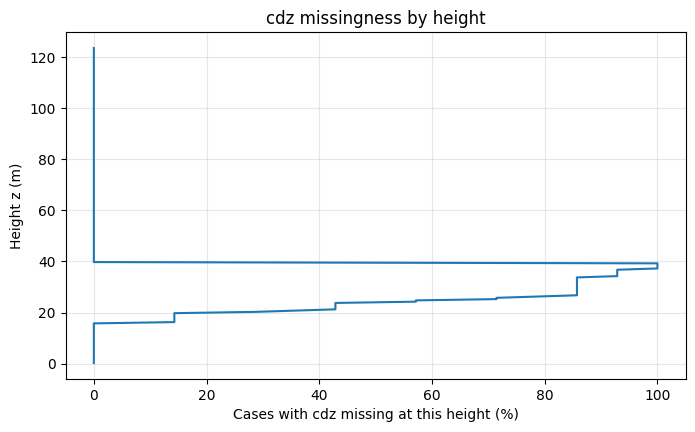

Other columns missing on the rows where cdz is missing (fraction):


,frac_missing
cdz,1.0
uGrad,0.0
lece,0.0
cklk,0.0
Km,0.0
formA,0.0


uGrad on cdz-missing vs cdz-present rows:


,count,mean,std,min,25%,50%,75%,max
cdz_na,,,,,,,,
False,21472.0,0.1235,0.1296,-0.1583,0.0602,0.0949,0.1365,3.2514
True,6976.0,0.1725,0.1753,0.0289,0.1034,0.1377,0.1886,3.9634


In [16]:
m_ = profiles.assign(cdz_na=profiles["cdz"].isna())
print("cdz missing after cleaning: %.1f%% of rows" % (m_["cdz_na"].mean() * 100))

by_case = m_.groupby("case")["cdz_na"].mean()
print("Cases with no cdz gap:", int((by_case == 0).sum()), "| cases entirely missing:", int((by_case == 1).sum()))

# is each case's gap one contiguous block, and where does it sit?
rows = []
for c, g in m_.sort_values(["case", "z"]).groupby("case"):
    idx = np.where(g["cdz_na"].values)[0]
    contiguous = (idx.max() - idx.min() + 1 == len(idx)) if len(idx) else True
    rows.append({"case": c, "gap_z_min": g["z"].iloc[idx.min()] if len(idx) else np.nan,
                 "gap_z_max": g["z"].iloc[idx.max()] if len(idx) else np.nan,
                 "gap_levels": len(idx), "contiguous": contiguous})
gaps = pd.DataFrame(rows).merge(meta.drop(columns=["lp_code"]), on="case")
print("Cases whose cdz gap is a single contiguous block:", int(gaps["contiguous"].sum()), "/", len(gaps))
print("Distinct gap upper bounds (z):", gaps["gap_z_max"].round(2).unique())

print("\nGap start / length by group:")
display(gaps.groupby("height_type")[["gap_z_min", "gap_z_max", "gap_levels"]].mean().round(1))
display(gaps.groupby("height_pattern", dropna=False)[["gap_z_min", "gap_z_max", "gap_levels"]].mean().round(1))
display(gaps.groupby("height_var", dropna=False)[["gap_z_min", "gap_z_max", "gap_levels"]].mean().round(1))
display(gaps.groupby("lambda_p")[["gap_z_min", "gap_z_max", "gap_levels"]].mean().round(1))

by_z = m_.groupby("z")["cdz_na"].mean()
plt.figure(figsize=(8, 4.5)); plt.plot(by_z.values * 100, by_z.index)
plt.xlabel("Cases with cdz missing at this height (%)"); plt.ylabel("Height z (m)")
plt.title("cdz missingness by height"); plt.grid(alpha=0.3); plt.show()

print("Other columns missing on the rows where cdz is missing (fraction):")
display(m_.loc[m_["cdz_na"], phys_cols].isna().mean().sort_values(ascending=False).head(6).round(3).to_frame("frac_missing"))
print("uGrad on cdz-missing vs cdz-present rows:")
display(m_.groupby("cdz_na")["uGrad"].describe().round(4))

## 12. Distributions and outlier inspection

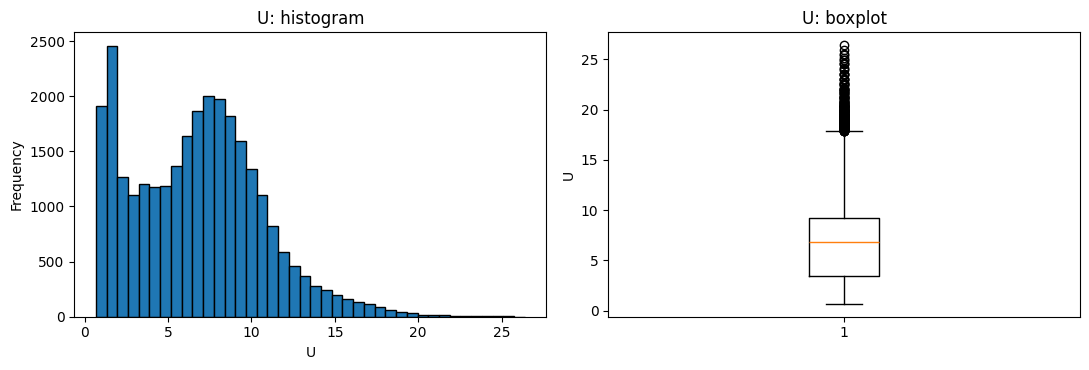

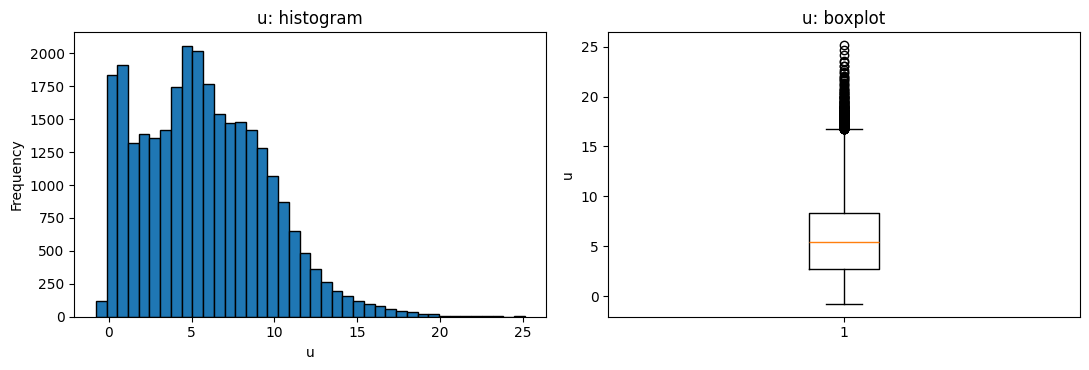

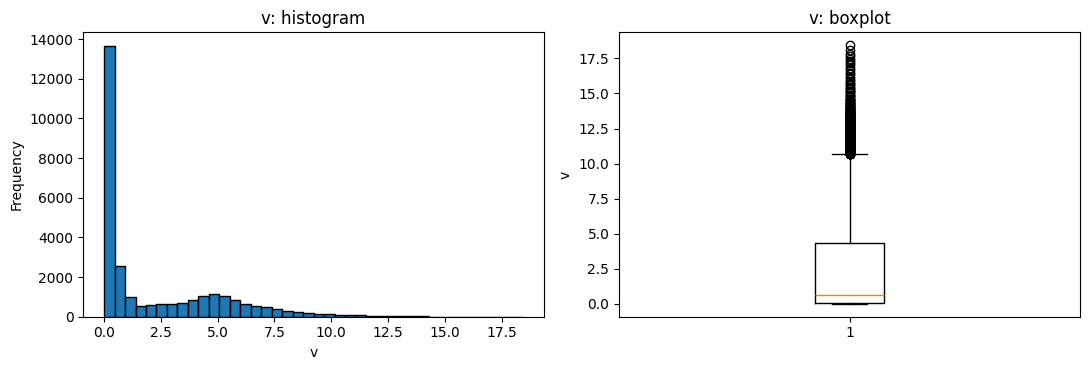

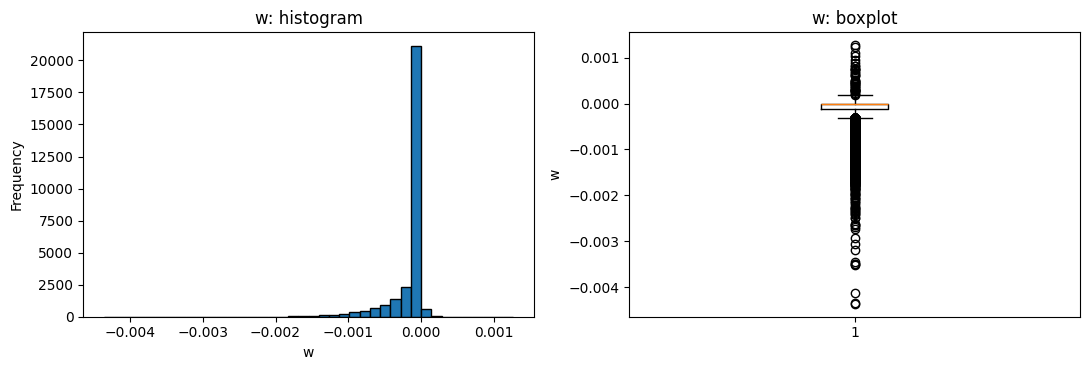

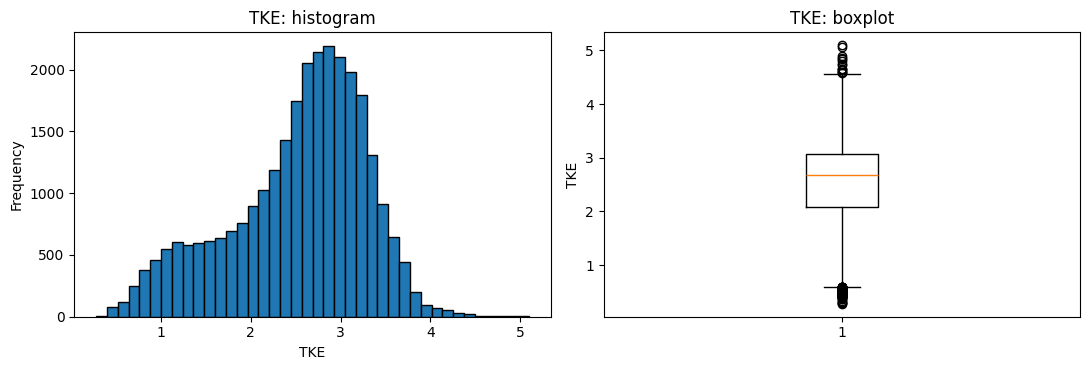

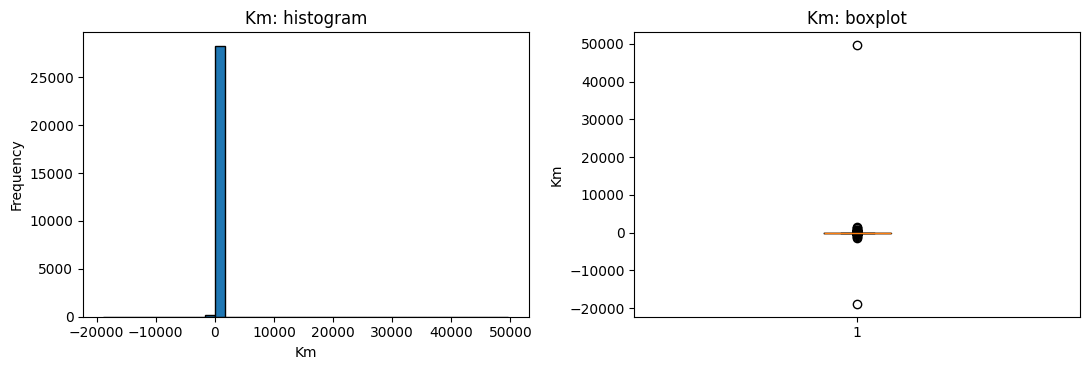

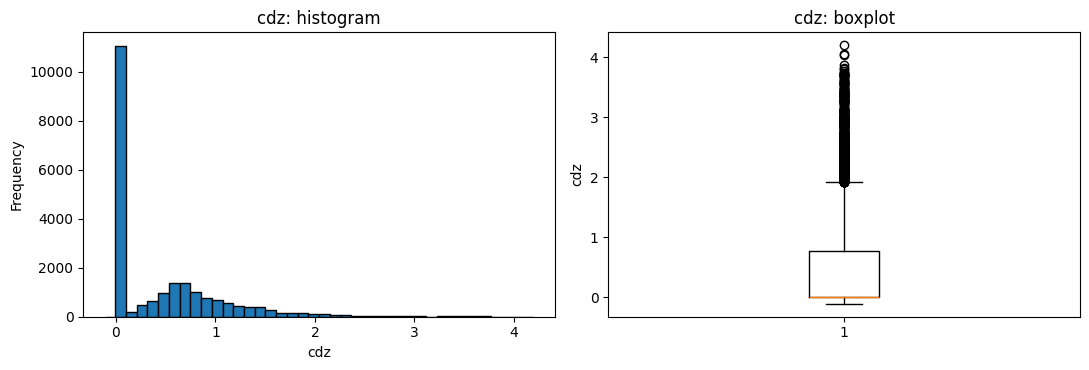

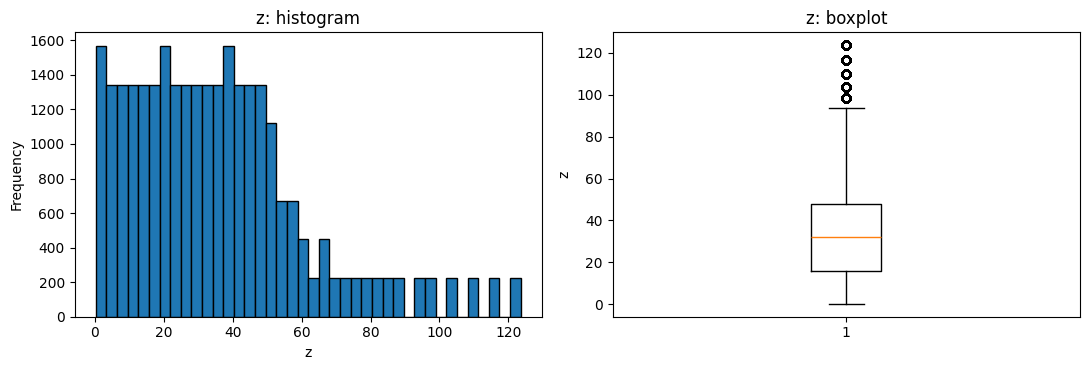

In [17]:
distribution_vars = [c for c in ["U", "u", "v", "w", "TKE", "Km", "cdz", "z"] if c in profiles.columns]

for var in distribution_vars:
    values = profiles[var].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].hist(values, bins=40, edgecolor="black")
    axes[0].set_title(f"{var}: histogram")
    axes[0].set_xlabel(var)
    axes[0].set_ylabel("Frequency")
    axes[1].boxplot(values, vert=True)
    axes[1].set_title(f"{var}: boxplot")
    axes[1].set_ylabel(var)
    plt.tight_layout()
    plt.show()

## 13. Correlation heatmap

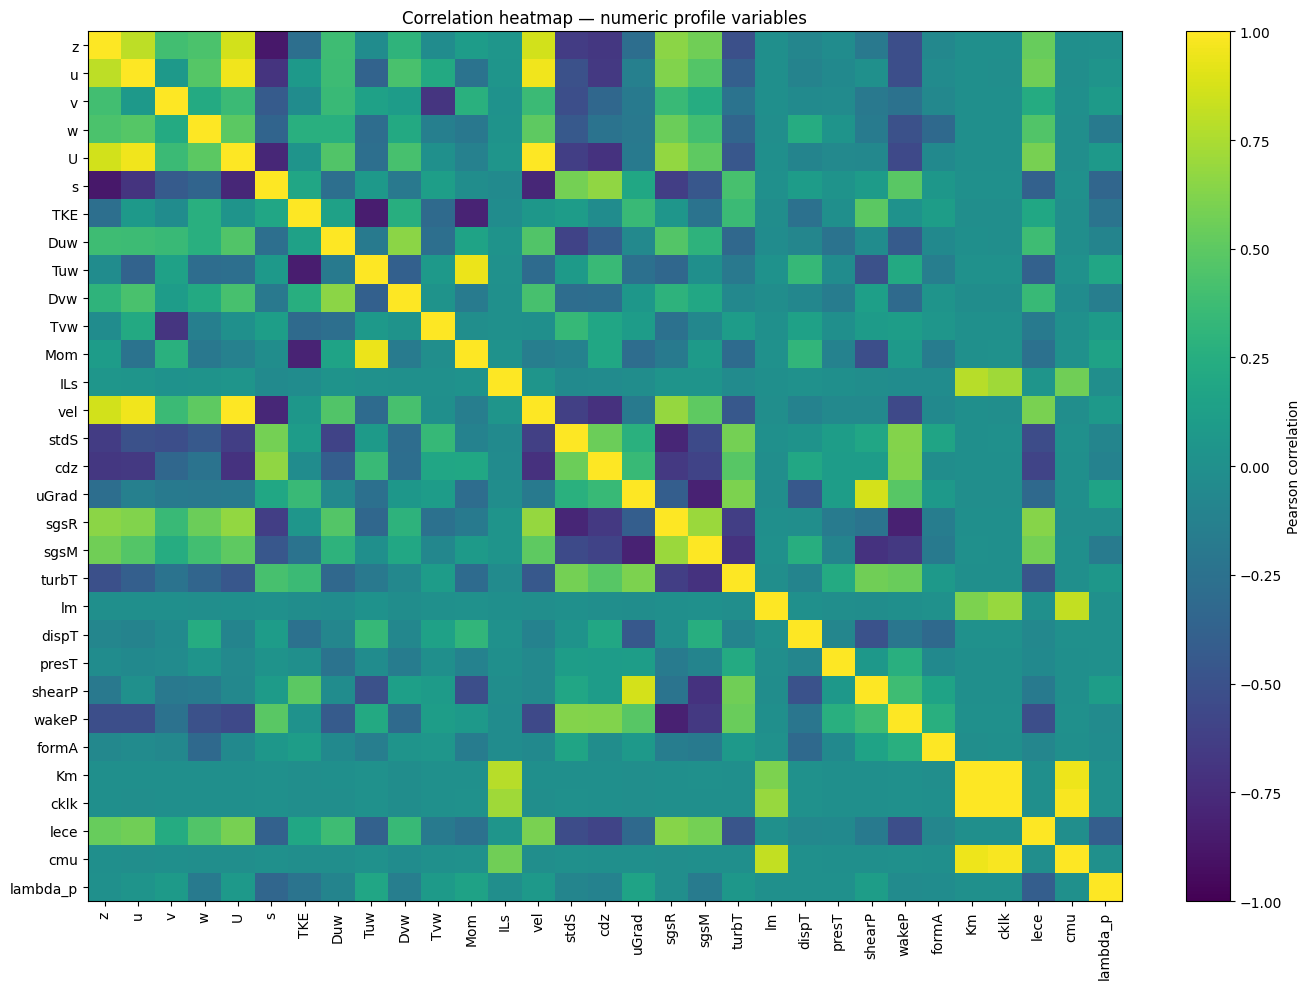

,variable_1,variable_2,correlation,abs_correlation
122,U,vel,0.999234,0.999234
455,Km,cklk,0.993958,0.993958
460,cklk,cmu,0.980376,0.980376
41,u,vel,0.955111,0.955111
32,u,U,0.954692,0.954692
457,Km,cmu,0.952959,0.952959
214,Tuw,Mom,0.942706,0.942706
366,uGrad,shearP,0.873127,0.873127
4,z,s,-0.871340,0.871340
3,z,U,0.861820,0.861820


In [31]:
numeric_cols = [
    c for c in profiles.select_dtypes(include=np.number).columns
    if c not in ["Unnamed: 0", "wind_deg"]
]
corr = profiles[numeric_cols].replace([np.inf, -np.inf], np.nan).corr(method="pearson", min_periods=30)

plt.figure(figsize=(14, 10))
im = plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(im, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation heatmap — numeric profile variables")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().rename("correlation").reset_index()
strong_pairs.columns = ["variable_1", "variable_2", "correlation"]
strong_pairs["abs_correlation"] = strong_pairs["correlation"].abs()
display(strong_pairs.sort_values("abs_correlation", ascending=False).head(20))

## 14. Optional physics-consistency checks

In [19]:
# These checks run only if the relevant columns exist.
if all(c in profiles.columns for c in ["Mom", "Tuw", "Duw"]):
    valid = profiles[["Mom", "Tuw", "Duw"]].notna().all(axis=1)
    residual = profiles.loc[valid, "Mom"] - profiles.loc[valid, "Tuw"] - profiles.loc[valid, "Duw"]
    print("Check Mom = Tuw + Duw")
    print("Rows checked:", int(valid.sum()))
    print("Median absolute residual:", residual.abs().median())
    print("95th percentile absolute residual:", residual.abs().quantile(0.95))
else:
    print("Skipped Mom = Tuw + Duw: one or more columns unavailable.")

if all(c in profiles.columns for c in ["Km", "Mom", "uGrad"]):
    valid = profiles[["Km", "Mom", "uGrad"]].notna().all(axis=1) & profiles["uGrad"].ne(0)
    residual = profiles.loc[valid, "Km"] - (-profiles.loc[valid, "Mom"] / profiles.loc[valid, "uGrad"])
    print("\nCheck Km = -Mom/uGrad")
    print("Rows checked with nonzero uGrad:", int(valid.sum()))
    print("Median absolute residual:", residual.abs().median())
    print("95th percentile absolute residual:", residual.abs().quantile(0.95))
else:
    print("Skipped Km = -Mom/uGrad: one or more columns unavailable.")

Check Mom = Tuw + Duw
Rows checked: 28672
Median absolute residual: 4.754226526348937e-17
95th percentile absolute residual: 1.205632815803881e-16

Check Km = -Mom/uGrad
Rows checked with nonzero uGrad: 28448
Median absolute residual: 7.993605777301127e-15
95th percentile absolute residual: 9.592326932761353e-14


## 14b. Spatial EDA (`_topo` and `_ped.nc`) — runs only if the files are in the ZIP

In [20]:
topo_files = sorted(n for n in all_names if "_topo" in n.lower())
ped_files  = sorted(n for n in all_names if n.lower().endswith("_ped.nc"))
print("topo files:", len(topo_files), "| _ped.nc files:", len(ped_files))
if not (topo_files and ped_files):
    print("SKIPPED: this ZIP contains only the profile CSVs. Upload the _topo and _ped.nc files for the 224 cases")
    print("to run: grid-shape consistency, NaN fraction inside/outside buildings, 1.75 m wind-speed distribution,")
    print("mean wind map per layout, topo/ped alignment, and lambda_p computed from topo.")
else:
    import xarray as xr, io
    with zipfile.ZipFile(ZIP_PATH) as zf:
        ds = xr.open_dataset(io.BytesIO(zf.read(ped_files[0])))
    print(ds)      # inspect variable names, then write the spatial analysis against them

topo files: 0 | _ped.nc files: 0
SKIPPED: this ZIP contains only the profile CSVs. Upload the _topo and _ped.nc files for the 224 cases
to run: grid-shape consistency, NaN fraction inside/outside buildings, 1.75 m wind-speed distribution,
mean wind map per layout, topo/ped alignment, and lambda_p computed from topo.


## 15. Automatically generated EDA findings

In [21]:
n_files = len(profile_names)
n_cases = profiles["case"].nunique()
n_rows = len(profiles)
n_cols_original = len([c for c in profiles.columns if c not in ["case", "wind_deg", "source_file"]])
rows_per_case = case_inventory["rows"]
non_130 = int((rows_per_case != 130).sum())

print("EDA FINDINGS — IDEALIZED PROFILE CSVs")
print("=" * 55)
print(f"Profile CSV files loaded: {n_files}")
print(f"Unique cases: {n_cases}")
print(f"Combined records: {n_rows:,}")
print(f"Original columns per file (expected): {n_cols_original}")
print(f"Cases with row count other than 130: {non_130}")

print("\nColumns with highest missingness:")
display(missing_summary.head(10))

if "wind_deg" in case_inventory.columns:
    print("\nCase counts by inferred wind direction:")
    display(case_inventory["wind_deg"].value_counts(dropna=False).rename_axis("wind_deg").reset_index(name="cases"))

print("\nCleaned rows per case:", profiles.groupby("case").size().unique(), "(z = 0 and top row removed)")
print("\nPedestrian-level U (z = 1.75 m) across cases:")
print(case_summary["U_ped_1p75"].describe().round(3))
print("Correlation of all-height mean U with U at 1.75 m (Spearman):",
      round(case_summary["U_mean"].corr(case_summary["U_ped_1p75"], method="spearman"), 3))

print("\nInterpretation reminders:")
print("- Missing values are reported, not imputed.")
print("- Outliers are displayed for review, not removed.")
print("- Correlations are descriptive; profile rows from one case are not independent cases.")
print("- Layout metadata (including lambda_p) is parsed from case names; verify against the handbook / _topo files.")
print("- Profile U at 1.75 m is a horizontally averaged profile value, not the 2D wind-map target.")
print("- Full spatial EDA requires matching _topo and _ped.nc files.")

EDA FINDINGS — IDEALIZED PROFILE CSVs
Profile CSV files loaded: 224
Unique cases: 224
Combined records: 28,672
Original columns per file (expected): 37
Cases with row count other than 130: 0

Columns with highest missingness:


,missing_count,missing_pct
cdz,6976,24.330357
height_var,4096,14.285714
height_pattern,4096,14.285714
turbT,448,1.562500
presT,448,1.562500
lm,397,1.384626
Km,224,0.781250
shearP,224,0.781250
uGrad,224,0.781250
formA,224,0.781250



Case counts by inferred wind direction:


,wind_deg,cases
0,0,112
1,45,112



Cleaned rows per case: [128] (z = 0 and top row removed)

Pedestrian-level U (z = 1.75 m) across cases:
count    224.000
mean       1.627
std        0.728
min        0.679
25%        1.094
50%        1.343
75%        1.963
max        3.933
Name: U_ped_1p75, dtype: float64
Correlation of all-height mean U with U at 1.75 m (Spearman): 0.04

Interpretation reminders:
- Missing values are reported, not imputed.
- Outliers are displayed for review, not removed.
- Correlations are descriptive; profile rows from one case are not independent cases.
- Layout metadata (including lambda_p) is parsed from case names; verify against the handbook / _topo files.
- Profile U at 1.75 m is a horizontally averaged profile value, not the 2D wind-map target.
- Full spatial EDA requires matching _topo and _ped.nc files.


## 16. Export EDA outputs

In [22]:
OUTPUT_DIR = "urbantales_idealized_eda_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

profiles.to_csv(os.path.join(OUTPUT_DIR, "combined_profiles_eda.csv"), index=False)
meta.to_csv(os.path.join(OUTPUT_DIR, "case_metadata_from_names.csv"), index=False)
gaps.to_csv(os.path.join(OUTPUT_DIR, "cdz_gap_by_case.csv"), index=False)
case_inventory.to_csv(os.path.join(OUTPUT_DIR, "case_inventory.csv"), index=False)
case_summary.to_csv(os.path.join(OUTPUT_DIR, "case_profile_summary.csv"), index=False)
missing_summary.to_csv(os.path.join(OUTPUT_DIR, "missing_values_summary.csv"))
strong_pairs.to_csv(os.path.join(OUTPUT_DIR, "strongest_correlations.csv"), index=False)

print("Saved files:")
for name in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", name)

Saved files:
 - case_inventory.csv
 - case_metadata_from_names.csv
 - case_profile_summary.csv
 - cdz_gap_by_case.csv
 - combined_profiles_eda.csv
 - missing_values_summary.csv
 - strongest_correlations.csv


## 17. Download the output tables

In [23]:
output_zip = shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)
print("Created:", output_zip)
try:
    from google.colab import files
    files.download(output_zip)
except ImportError:
    pass

Created: /Users/neerajsingh/Urban-Microclimate-Modelling/pipeline/S04_eda/urbantales_idealized_eda_outputs.zip


In [33]:
from pathlib import Path

FIGURES_DIR = Path.cwd() / "pipeline" / "S04_eda" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save the graph before displaying it
fig.savefig(
    FIGURES_DIR / "per_case_profile_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Conclusions and limitations

Conclusions should be written from the printed tables and plots above; correlations are descriptive, not causal.

- Profile rows from the same case are not independent, so analyse at case level.
- λp, layout and height pattern come from the case names and must be confirmed against the handbook or computed from `_topo`.
- The cdz gap section describes where and how the gap occurs; it does not by itself establish the physical cause.
- This notebook does not perform preprocessing, feature engineering, splitting or model training, and the spatial-field EDA needs the `_topo` and `_ped.nc` files.